# Exploratory Data Analysis (EDA)

## Introduction

After successfully merging the two collected datasets, we obtained a unified dataset containing both game identifiers/names and their corresponding metadata (description, developer, publisher, genres, pricing, recommendations, release date, etc.).

During the merge, **only 4 games were excluded** because they were present in the `Game_ID`/`Game_Name` dataset but had **no corresponding records in the metadata dataset**. Given that the final dataset contains **10,496 games**, removing only four entries has a negligible impact on the overall analysis and data quality.

### Merge Summary
- Initial merged candidate records: **10,500**
- Records removed due to missing metadata: **4**
- Final dataset for analysis: **10,496 games**

---

## Exploratory Data Analysis (EDA)

The next step is to perform Exploratory Data Analysis (EDA) to better understand the dataset before any preprocessing or modeling. The analysis will include:

- Importing the required Python libraries.
- Loading the merged dataset.
- Inspecting the dataset structure.
- Checking data types and missing values.
- Generating descriptive statistics.
- Exploring the distributions of numerical and categorical features.
- Identifying potential outliers and inconsistencies.
- Examining relationships between important variables.

This exploratory analysis will provide insights into the characteristics of the Steam games dataset and guide the preprocessing and feature engineering steps required for building the recommendation system.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df = pd.read_csv(r'D:\Projects\games-recommender-system\data\processed\Final_Dataset.csv')
df.shape

(10496, 13)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10496 entries, 0 to 10495
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Game_ID                    10496 non-null  int64  
 1   Game_Name                  10495 non-null  str    
 2   Is_Free                    10496 non-null  bool   
 3   Description                10490 non-null  str    
 4   Supported_Languages        10489 non-null  str    
 5   Developer                  10449 non-null  str    
 6   Publishers                 10300 non-null  str    
 7   Price                      9422 non-null   str    
 8   Genre                      10469 non-null  str    
 9   Metacritic_Score           2592 non-null   float64
 10  Category                   10493 non-null  str    
 11  Number_of_Recommendations  5703 non-null   float64
 12  Release_Date               10443 non-null  str    
dtypes: bool(1), float64(2), int64(1), str(9)
memory usage: 99

In [13]:
df.isnull().sum()

Game_ID                         0
Game_Name                       1
Is_Free                         0
Description                     6
Supported_Languages             7
Developer                      47
Publishers                    196
Price                        1074
Genre                          27
Metacritic_Score             7904
Category                        3
Number_of_Recommendations    4793
Release_Date                   53
dtype: int64

## Data Preprocessing

Before analysis and model development, the dataset will undergo preprocessing to improve data quality.

The preprocessing steps include:

* **Handling missing values** by removing or imputing `NULL` values where appropriate.
* **Converting data types** to suitable formats, such as converting `Price` to numeric and `Release_Date` to datetime, while ensuring all columns have appropriate data types for analysis.

These steps will prepare the dataset for subsequent analysis and recommender system development.


### Dropping Critical Missing Values

Rows with missing values in **`Game_Name`** and **`Description`** were removed, as these columns are essential for identifying and describing each game. Since they contained only **1** and **7** missing values, respectively, dropping these rows had a negligible impact on the dataset.


In [14]:
df[df['Game_Name'].isnull()]

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Metacritic_Score,Category,Number_of_Recommendations,Release_Date
6930,396420,NaN,True,Spookeningは3Dの恐怖ゲームで、あなたは毎夜に死んでゴーストとして復活します。 村...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1 Nov, 2016"


In [15]:
df = df.dropna(subset=['Game_Name'])
df.shape

(10495, 13)

In [16]:
df[df['Description'].isnull()]

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Metacritic_Score,Category,Number_of_Recommendations,Release_Date
2007,224880,Equate Game,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': 2, 'description': 'Single-player'}, {'...",NaN,NaN
5092,345950,Down To One Dedicated Server,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': 62, 'description': 'Family Sharing'}]",NaN,"26 Jan, 2015"
6450,382990,BrainBread 2 Mod Tools,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': 62, 'description': 'Family Sharing'}]",NaN,"17 Feb, 2016"
7001,398040,Postmaster Legacy,False,NaN,English,['Crunchy Sushi'],['Crunchy Sushi'],NaN,"[{'id': '1', 'description': 'Action'}, {'id': ...",NaN,"[{'id': 2, 'description': 'Single-player'}, {'...",NaN,NaN
8328,439660,Tower Unite Dedicated Server,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': 62, 'description': 'Family Sharing'}]",NaN,"29 Mar, 2016"
8726,451330,IS Defense Editor,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"29 Apr, 2016"


In [17]:
df = df.dropna(subset=['Description'])
df.shape

(10489, 13)

### Imputing Missing Supported Languages

Missing values in **`Supported_Languages`** were filled using the **mode** of the column. This approach is appropriate because the vast majority of games support **English**, making the most frequent value a reasonable replacement for missing entries.


In [18]:
df[df['Supported_Languages'].isnull()].head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Metacritic_Score,Category,Number_of_Recommendations,Release_Date
4794,338640,Subsiege,False,Subsiege is an intense real-time tactic game w...,NaN,['Icebird Studios'],['Icebird Studios'],$19.99 USD,NaN,NaN,"[{'id': 62, 'description': 'Family Sharing'}]",NaN,"7 Sep, 2018"


In [19]:
df['Supported_Languages'].mode()

0    English
Name: Supported_Languages, dtype: str

In [20]:
df['Supported_Languages'] = df['Supported_Languages'].fillna(df['Supported_Languages'].mode()[0])

In [21]:
df[df['Supported_Languages'].isnull()]

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Metacritic_Score,Category,Number_of_Recommendations,Release_Date


### Imputing Missing Developers and Publishers

Missing values in **`Developer`** and **`Publishers`** were filled with **`Unknown`**. These features are important for the recommender system, and replacing missing values with the mode could introduce bias by incorrectly assigning games to existing developers or publishers. Using `Unknown` preserves the missing information without distorting the data distribution.


In [22]:
df['Publishers'] = df['Publishers'].fillna('Unknown')
df['Developer'] = df['Developer'].fillna('Unknown')

In [23]:
df.isnull().sum()

Game_ID                         0
Game_Name                       0
Is_Free                         0
Description                     0
Supported_Languages             0
Developer                       0
Publishers                      0
Price                        1067
Genre                          21
Metacritic_Score             7897
Category                        1
Number_of_Recommendations    4786
Release_Date                   51
dtype: int64

### Dropping Missing Genre and Category Values

Rows with missing values in **`Genre`** and **`Category`** were removed, as these features are essential for content-based recommendations. Since only a small number of records contained missing values, dropping them had minimal impact on the dataset.


In [24]:
df = df.dropna(subset=['Genre', 'Category'])

### Dropping the Metacritic Score Column

The **`Metacritic_Score`** column was removed because it contained **7,897** missing values, representing a substantial portion of the dataset. Due to the high percentage of missing data, the column was considered unreliable and unlikely to provide meaningful value for the recommender system.


In [25]:
df = df.drop(columns=['Metacritic_Score'])
df = df.dropna(subset=['Release_Date'])
df.isnull().sum()

Game_ID                         0
Game_Name                       0
Is_Free                         0
Description                     0
Supported_Languages             0
Developer                       0
Publishers                      0
Price                        1027
Genre                           0
Category                        0
Number_of_Recommendations    4751
Release_Date                    0
dtype: int64

### Handling Missing Price Values

Many missing values in the **`Price`** column correspond to free games. Therefore, games with **`Is_Free = True`** and a missing price were assigned a value of **`0.00`**. This ensures that free games are accurately represented while reducing the number of missing values in the `Price` column.


In [ ]:
df.loc[df['Is_Free'] == True, 'Price'] = '0.00'
df.isnull().sum()                   

Game_ID                         0
Game_Name                       0
Is_Free                         0
Description                     0
Supported_Languages             0
Developer                       0
Publishers                      0
Price                         163
Genre                           0
Category                        0
Number_of_Recommendations    4751
Release_Date                    0
dtype: int64

### Dropping Remaining Missing Price Values

After assigning a price of **`0.00`** to free games, the remaining rows with missing values in the **`Price`** column were removed. These records lacked valid pricing information and could not be reliably imputed without introducing inaccuracies into the dataset.


In [27]:
df = df.dropna(subset=['Price'])
df.isnull().sum()

Game_ID                         0
Game_Name                       0
Is_Free                         0
Description                     0
Supported_Languages             0
Developer                       0
Publishers                      0
Price                           0
Genre                           0
Category                        0
Number_of_Recommendations    4634
Release_Date                    0
dtype: int64

In [28]:
df.shape

(10256, 12)

In [29]:
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English<strong>*</strong>, French<strong>*</st...",['Valve'],['Valve'],$5.79 USD,"[{'id': '1', 'description': 'Action'}]","[{'id': 1, 'description': 'Multi-player'}, {'i...",168033.0,"1 Nov, 2000"


In [30]:
df['Developer'].apply(eval)
df.head(1)

NameError: name 'Unknown' is not defined

## Cleaning Developer and Publisher Data

The **`Developer`** and **`Publishers`** columns contained values stored as string representations of Python lists (e.g., `['Valve', 'Hidden Path Entertainment']`). To standardize these fields, the string representations were first converted into Python list objects. The elements within each list were then joined into a single comma-separated string.

This transformation produced a cleaner and more consistent format, making the data easier to read, analyze, and use in the recommender system.


In [31]:
def self_eval(val):
    try:
        return eval(val)
    except:
        return val


In [32]:
df['Publishers'] = df['Publishers'].apply(self_eval)

In [33]:
df['Developer'] = df['Developer'].apply(lambda x: ','.join(x) if isinstance(x, list) else x)
df['Publishers'] = df['Publishers'].apply(lambda x: ','.join(x) if isinstance(x, list) else x)
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English<strong>*</strong>, French<strong>*</st...",['Valve'],Valve,$5.79 USD,"[{'id': '1', 'description': 'Action'}]","[{'id': 1, 'description': 'Multi-player'}, {'i...",168033.0,"1 Nov, 2000"


In [34]:
df['Price'] = df['Price'].str.replace('$','')

In [35]:
df['Price'] = df['Price'].str.replace('USD','')

In [36]:
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English<strong>*</strong>, French<strong>*</st...",['Valve'],Valve,5.79,"[{'id': '1', 'description': 'Action'}]","[{'id': 1, 'description': 'Multi-player'}, {'i...",168033.0,"1 Nov, 2000"


In [37]:
df['Genre'] = df['Genre'].apply(self_eval)
df['Genre'] = df['Genre'].apply(lambda x: ','.join(item['description'] for item in x) if isinstance(x, list) else x)

In [38]:
df.tail()

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
10491,509160,Gebub's Adventure,False,"Gebub finds himself in a large peaceful world,...",English,['John Wallie'],John Wallie,4.99,Adventure,"[{'id': 2, 'description': 'Single-player'}, {'...",NaN,"16 Aug, 2016"
10492,509170,VRNinja,False,VRNinja is a fast-paced virtual reality game t...,English,['OutOfBounds Software Solutions Inc'],OutOfBounds Software Solutions Inc,9.99,"Action,Casual,Indie,Simulation","[{'id': 2, 'description': 'Single-player'}, {'...",NaN,"14 Sep, 2016"
10493,509190,Rollout,True,Rollout is a multiplayer &quot;eat-to-grow&quo...,English,['Ryan up in here'],Ryan up in here,0.00,"Action,Casual,Free To Play,Indie,Early Access","[{'id': 1, 'description': 'Multi-player'}, {'i...",NaN,"14 Sep, 2016"
10494,509210,Clockwork,False,Clockwork is a time-bending puzzle-platformer ...,English,['Gamesoft'],Gamesoft,2.99,"Action,Adventure,Casual,Indie,Strategy","[{'id': 2, 'description': 'Single-player'}, {'...",NaN,"10 Oct, 2016"
10495,509220,Save Jesus,False,Someone is trying to murder Jesus. Disguised a...,English<strong>*</strong><br><strong>*</strong...,['Almighty Games'],My Way Games,4.49,"Casual,Indie","[{'id': 2, 'description': 'Single-player'}, {'...",1478.0,"4 Aug, 2016"


In [40]:
df['Category'] = df['Category'].apply(self_eval)
df['Category'] = df['Category'].apply(lambda x: ','.join(item['description'] for item in x) if isinstance(x, list) else x)

In [41]:
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English<strong>*</strong>, French<strong>*</st...",['Valve'],Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,"1 Nov, 2000"


In [42]:
df['Developer'] = df['Developer'].apply(self_eval)

In [44]:
df['Developer'] = df['Developer'].apply(lambda x: ','.join(x) if isinstance(x, list) else x)
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English<strong>*</strong>, French<strong>*</st...",Valve,Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,"1 Nov, 2000"


## Cleaning Text Data

The **`Supported_Languages`** and **`Description`** columns were cleaned by removing unnecessary special characters, punctuation, and formatting symbols. This preprocessing step standardizes the text, reduces noise, and improves its suitability for text analysis and feature extraction in the recommender system.


In [45]:
import re
df['Supported_Languages'] = df['Supported_Languages'].str.replace('<[^>]+>', '', regex=True)
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English*, French*, German*, Italian*, Spanish ...",Valve,Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,"1 Nov, 2000"


In [46]:
df['Supported_Languages'] = df['Supported_Languages'].str.replace('*', '', regex=False)
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English, French, German, Italian, Spanish - Sp...",Valve,Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,"1 Nov, 2000"


In [49]:
import html
df['Description'] = df['Description'].apply(html.unescape)
df['Description'].str.contains('&amp;|&quot;|&lt;|&gt;').sum()

np.int64(0)

In [50]:
df['Release_Date'].dtype


<StringDtype(storage='python', na_value=nan)>

## Final Data Type Conversion

As the final preprocessing step, the **`Release_Date`** column was converted from a string to the **datetime** data type, and the **`Price`** column was converted from a string to **float**. These conversions ensure that temporal and numerical operations can be performed efficiently.

After completing these preprocessing and cleaning steps, the dataset is fully processed, consistent, and ready for exploratory data analysis and recommender system development.


In [53]:
df['Release_Date'] = pd.to_datetime(df['Release_Date'], format= 'mixed', errors= 'coerce')

In [54]:
df.dtypes

Game_ID                               int64
Game_Name                               str
Is_Free                                bool
Description                             str
Supported_Languages                     str
Developer                               str
Publishers                              str
Price                                   str
Genre                                   str
Category                                str
Number_of_Recommendations           float64
Release_Date                 datetime64[us]
dtype: object

In [56]:
df['Price'] = df['Price'].str.extract(r'(\d+\.?\d*)').astype(float)
df.dtypes

Game_ID                               int64
Game_Name                               str
Is_Free                                bool
Description                             str
Supported_Languages                     str
Developer                               str
Publishers                              str
Price                               float64
Genre                                   str
Category                                str
Number_of_Recommendations           float64
Release_Date                 datetime64[us]
dtype: object

In [ ]:
df.dropna(subset=['Release_Date'], inplace= True)
df.isnull().sum()

Game_ID                         0
Game_Name                       0
Is_Free                         0
Description                     0
Supported_Languages             0
Developer                       0
Publishers                      0
Price                           0
Genre                           0
Category                        0
Number_of_Recommendations    4627
Release_Date                    0
dtype: int64

In [59]:
df.shape

(10249, 12)

In [61]:
df.to_csv(r"D:\Projects\games-recommender-system\data\processed\Clean_Steam.csv", index=False)

## Exploratory Data Analysis

After cleaning and preprocessing the dataset, we will explore the main patterns and relationships within the data.

### Distribution Plots

- **Price distribution**
- **Recommendations distribution**
- **Games released per year**

### Categorical Analysis

- **Top 10 genres**
- **Top 10 categories**
- **Free vs. paid games ratio**
- **Top 10 developers by number of games**

### Correlation Analysis

- **Price vs. Recommendations** — Do more expensive games receive more recommendations?
- **Release Year vs. Recommendations** — Are newer games more popular?

These visualizations will help us understand the dataset's **overall distribution, common game characteristics, and relationships between important features**, providing useful insights for the recommender system.

In [2]:
df = pd.read_csv(r'D:\Projects\games-recommender-system\data\processed\Clean_Steam.csv')
df.head(1)

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,False,Play the world's number 1 online action game. ...,"English, French, German, Italian, Spanish - Sp...",Valve,Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,2000-11-01


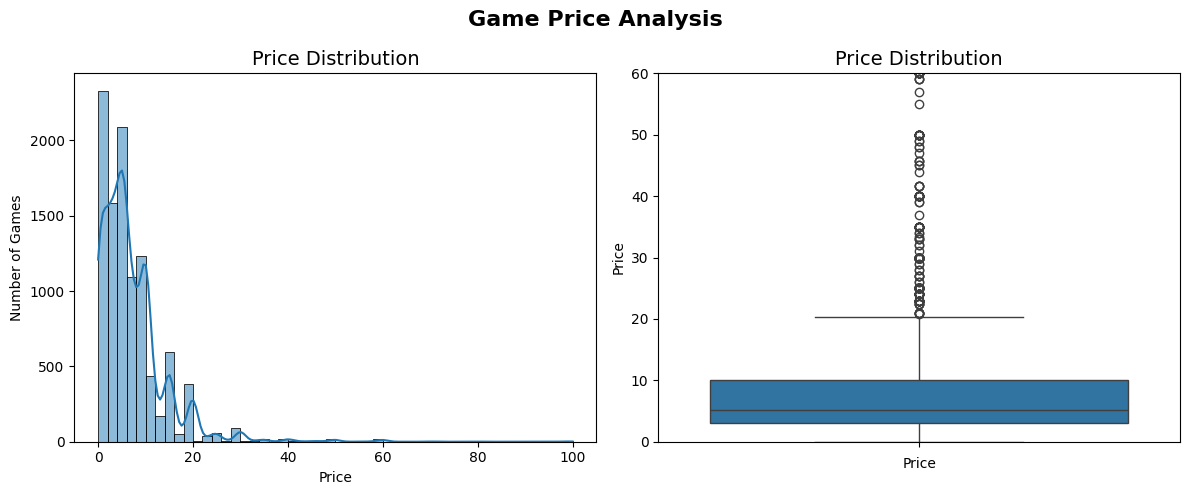

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(x= df['Price'], ax = axes[0], bins= 50, kde= True)
axes[0].set_title('Price Distribution', fontsize = 14)
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Number of Games')


sns.boxplot(y= df['Price'], ax= axes[1])
axes[1].set_title('Price Distribution', fontsize = 14)
axes[1].set_xlabel('Price')
axes[1].set_ylim(0,60)

fig.suptitle('Game Price Analysis', fontsize=16, fontweight='bold')
fig.tight_layout()
plt.show()


### Price Distribution Analysis

The price distribution is **right-skewed**, with most games concentrated in the lower price range. The majority of games are priced below **$20**, while only a small number of games have significantly higher prices.

The box plot also shows a large number of **outliers above $20**, with some games reaching prices close to **$60**. This indicates that game prices vary considerably, but most games remain relatively inexpensive.

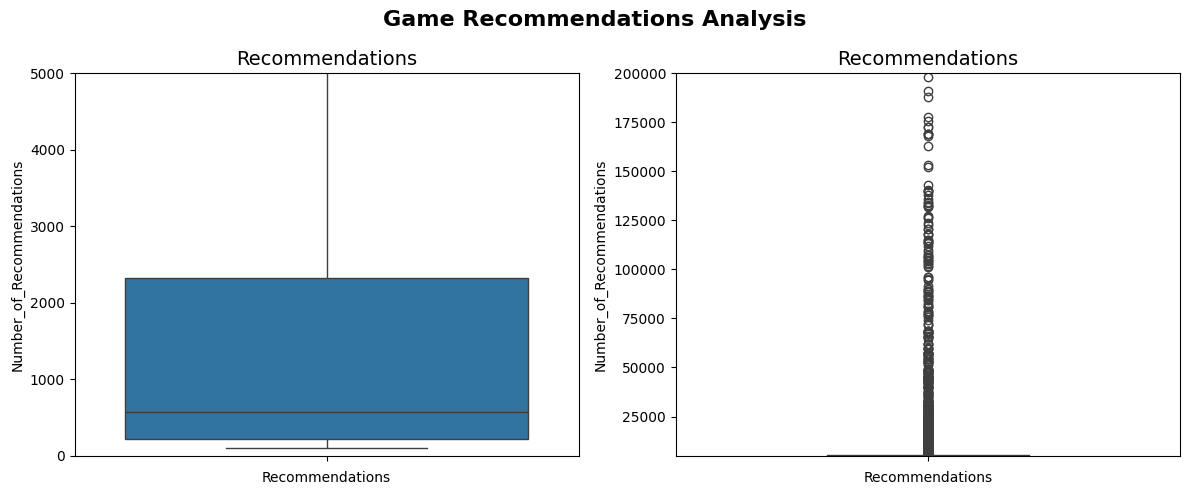

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y= df['Number_of_Recommendations'].dropna(), ax= axes[0])
axes[0].set_title('Recommendations', fontsize = 14)
axes[0].set_xlabel('Recommendations')
axes[0].set_ylim(0,5000)


sns.boxplot(y= df['Number_of_Recommendations'].dropna(), ax= axes[1])
axes[1].set_title('Recommendations', fontsize = 14)
axes[1].set_xlabel('Recommendations')
axes[1].set_ylim(5000,200000)


fig.suptitle('Game Recommendations Analysis', fontsize=16, fontweight='bold')
fig.tight_layout()
plt.show()


## 📊 Game Recommendations Analysis

Recommendations on Steam follow an **extreme right-skewed distribution**, revealing a stark divide between blockbuster and indie titles:

- The **majority of games** receive fewer than **2,500 recommendations**, with a median sitting well below 1,000
- A small group of **highly popular titles** accumulate tens of thousands to hundreds of thousands of recommendations
- This power-law distribution is typical in gaming markets — a few hits dominate while most titles remain niche

> A histogram was initially attempted but proved ineffective — the extreme skewness caused the distribution to collapse near zero, making the chart unreadable even with axis limiting and log scaling. Two box plots at different scales were used instead to better capture both the typical range and the outlier behavior.

> This skewness will be an important consideration during modeling — raw recommendation counts will likely need **log transformation** before use as a feature.

In [11]:
df.dtypes

Game_ID                        int64
Game_Name                        str
Is_Free                         bool
Description                      str
Supported_Languages              str
Developer                        str
Publishers                       str
Price                        float64
Genre                            str
Category                         str
Number_of_Recommendations    float64
Release_Date                     str
dtype: object

In [12]:
df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')
df['Release_Date'].dt.year

0        2000
1        1999
2        2003
3        2001
4        1999
         ... 
10244    2016
10245    2016
10246    2016
10247    2016
10248    2016
Name: Release_Date, Length: 10249, dtype: int32

In [13]:
games_per_year = df['Release_Date'].dt.year.value_counts().sort_index()
print(games_per_year)

Release_Date
1997       2
1998       1
1999       2
2000       2
2001       5
2002       1
2003       4
2004       3
2005       6
2006      58
2007      76
2008     129
2009     280
2010     223
2011     336
2012     536
2013     508
2014    1458
2015    2373
2016    2753
2017     694
2018     294
2019     177
2020     103
2021      63
2022      39
2023      35
2024      39
2025      36
2026      13
Name: count, dtype: int64


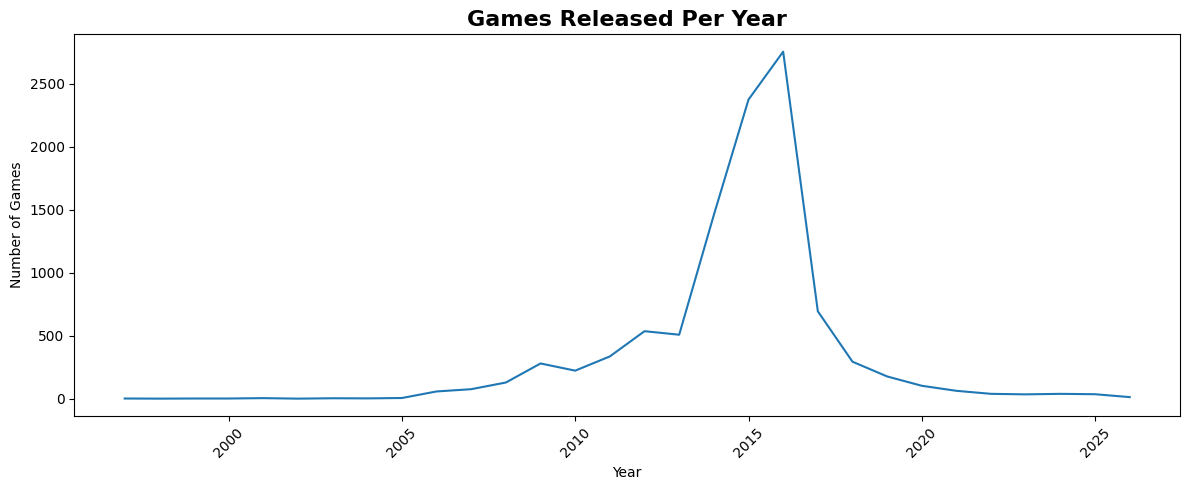

In [14]:
plt.figure(figsize=(12,5))
sns.lineplot(x= games_per_year.index, y= games_per_year.values)
plt.title('Games Released Per Year', fontsize=16, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusion

The number of games released per year increased significantly over time, with a sharp rise starting around 2013. The number of releases reached its peak in 2016 mainly due to the Steam Greenlight system which allowed indie developers to submit their game on steam, with more than 2,500 games released which makes sense as per those years were revolutionary for the gaming world starting from  games like metal gear rising, the last of us till The Witcher and Overwatch. After 2016, game releases declined considerably and continued to decrease through the following years, however, the reason can be how we collected and cleaned the data not that number of games per year released was decreased. Overall, the data shows a major expansion in game releases during the early-to-mid 2010s, followed by a substantial decline after the peak.

In [15]:
df['Genre'].str.split(',').explode().value_counts().head(10)

Genre
Indie           6816
Action          4755
Adventure       3821
Casual          2932
Strategy        2344
RPG             1827
Simulation      1809
Free To Play     551
Early Access     471
Racing           404
Name: count, dtype: int64

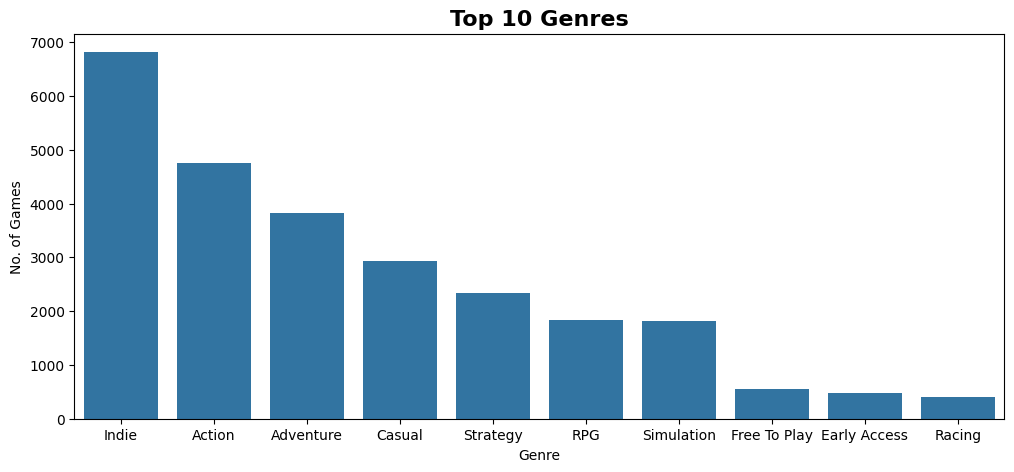

In [17]:
top_genres = df['Genre'].str.split(',').explode().value_counts().head(10)
plt.figure(figsize=(12,5))

sns.barplot(x= top_genres.index, y= top_genres.values)
plt.title('Top 10 Genres', fontsize = 16, fontweight= 'bold')
plt.xlabel('Genre')
plt.ylabel('No. of Games')
plt.show()

### Conclusion

Indie is the most common genre in the dataset by a significant margin, followed by Action and Adventure. Casual and Strategy games also have a relatively high number of releases, while RPG and Simulation appear less frequently. Free To Play, Early Access, and Racing are the least common among the top 10 genres. Overall, the distribution shows a strong dominance of Indie and Action games.

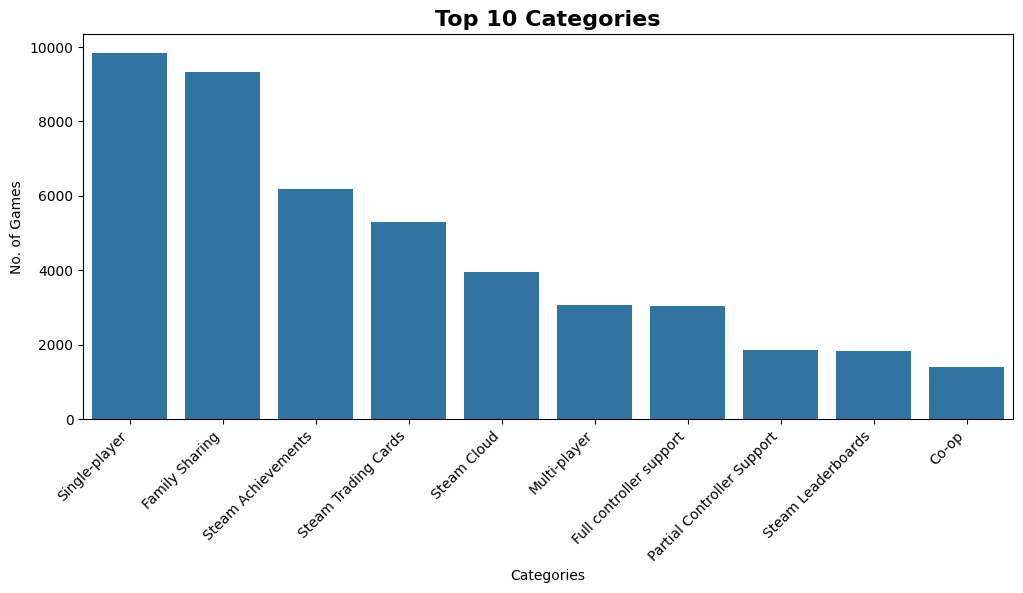

In [20]:
top_categories = df['Category'].str.split(',').explode().value_counts().head(10)
plt.figure(figsize=(12,5))

sns.barplot(x= top_categories.index, y= top_categories.values)
plt.title('Top 10 Categories', fontsize = 16, fontweight= 'bold')
plt.xlabel('Categories')
plt.ylabel('No. of Games')
plt.xticks(rotation=45, ha='right')
plt.show()

### Conclusion

Single-player is the most common Category in the dataset by a significant margin along side with Family Sharing, followed by Steam Achievement and Cloud. Multi-player and Full controller support games also have a relatively high number of releases, while Partial Controller Support, Steam Leaderboards and Co-op appear less frequently. Overall, the distribution shows a strong dominance of Single-player and Family Sharing games.

In [21]:
df['Is_Free'].value_counts()

Is_Free
False    9390
True      859
Name: count, dtype: int64

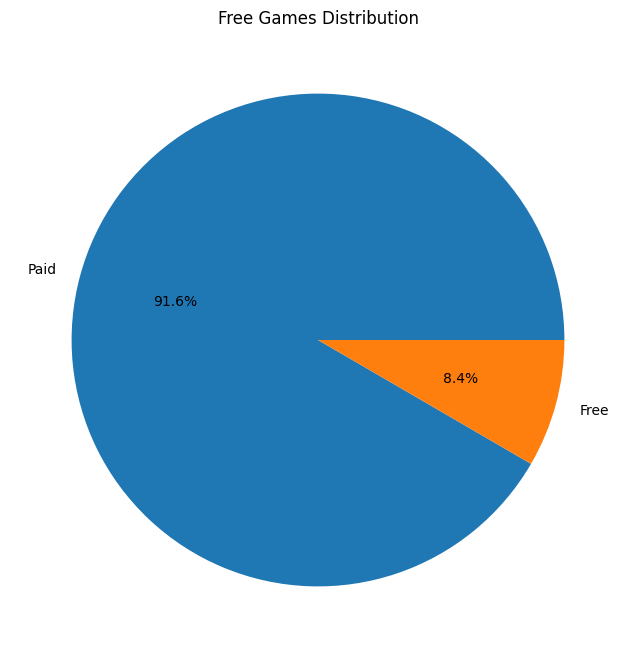

In [23]:
Free_games = df['Is_Free'].value_counts()
labels = ['Paid', 'Free'] if Free_games.index[0] == False else ['Free', 'Paid']
plt.figure(figsize=(8,8))
plt.pie(Free_games, labels= labels, autopct= '%1.1f%%')
plt.title('Free Games Distribution')
plt.show()

### Conclusion
this Shows that 8.4% of the games are free while 91.6% is Paid which makes sense as most of the free games are the online ones or limited time offers as steam is mainly for selling games

In [29]:
df['Developer'].value_counts().head(10)

Developer
Unknown                    40
MumboJumbo                 37
Humongous Entertainment    36
Choice of Games            30
Daedalic Entertainment     25
Spiderweb Software         25
HeR Interactive            24
PopCap Games, Inc.         23
Dharker Studios            23
Valve                      20
Name: count, dtype: int64

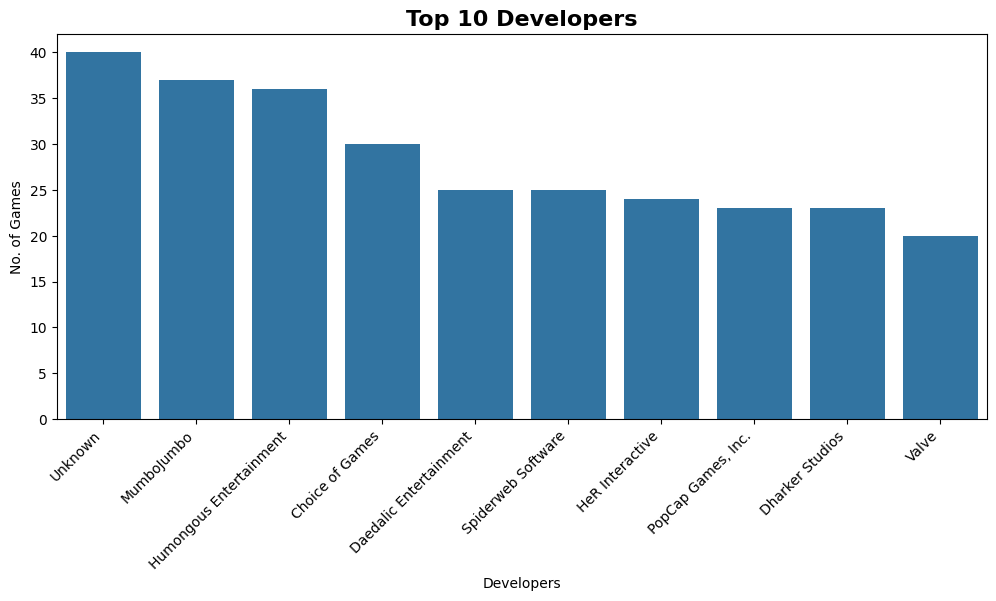

In [31]:
top_developers = df['Developer'].value_counts().head(10)
plt.figure(figsize=(12,5))

sns.barplot(x= top_developers.index, y= top_developers.values)
plt.title('Top 10 Developers', fontsize = 16, fontweight= 'bold')
plt.xlabel('Developers')
plt.ylabel('No. of Games')
plt.xticks(rotation=45, ha='right')
plt.show()

### Conclusion
most of the games are developed by unknown developers or missing data, however, MumboJumbo participated with the most games developed with score of 40 games followed by Humongous Entertainment with 36 games and valve managed to stay in top 10 with 20 games

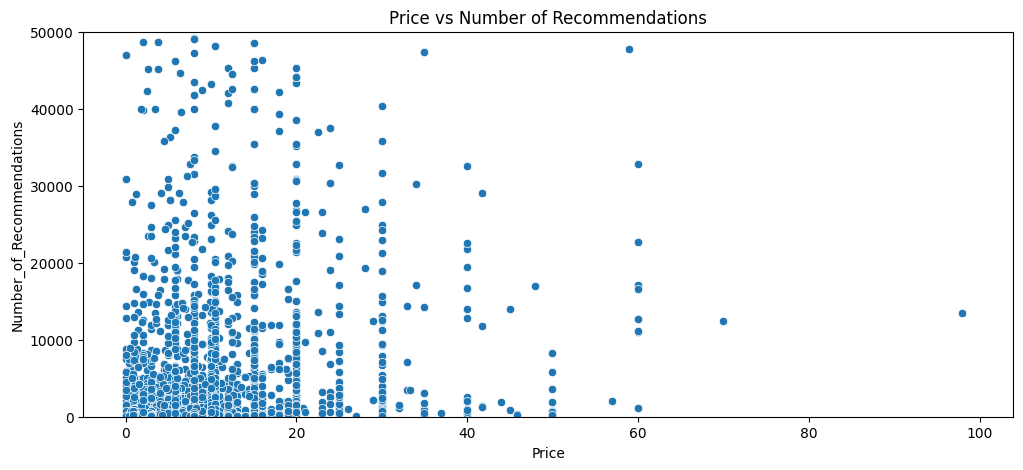

In [33]:
plt.figure(figsize=(12,5))
sns.scatterplot(data = df, x = 'Price', y = 'Number_of_Recommendations')
plt.title('Price vs Number of Recommendations')
plt.ylim(0, 50000)
plt.show()

### Conclusion

The scatter plot reveals that games priced between $0-$20 tend to accumulate the highest number of recommendations, which aligns with the earlier finding that most Steam games are in this price range. However, price alone does not appear to be a strong driver of recommendations — several higher-priced games ($40-$60+) still managed to gather significant recommendations, suggesting that game quality, popularity, and genre play a more important role than price in driving user engagement.

In [34]:
df.dtypes

Game_ID                               int64
Game_Name                               str
Is_Free                                bool
Description                             str
Supported_Languages                     str
Developer                               str
Publishers                              str
Price                               float64
Genre                                   str
Category                                str
Number_of_Recommendations           float64
Release_Date                 datetime64[us]
dtype: object

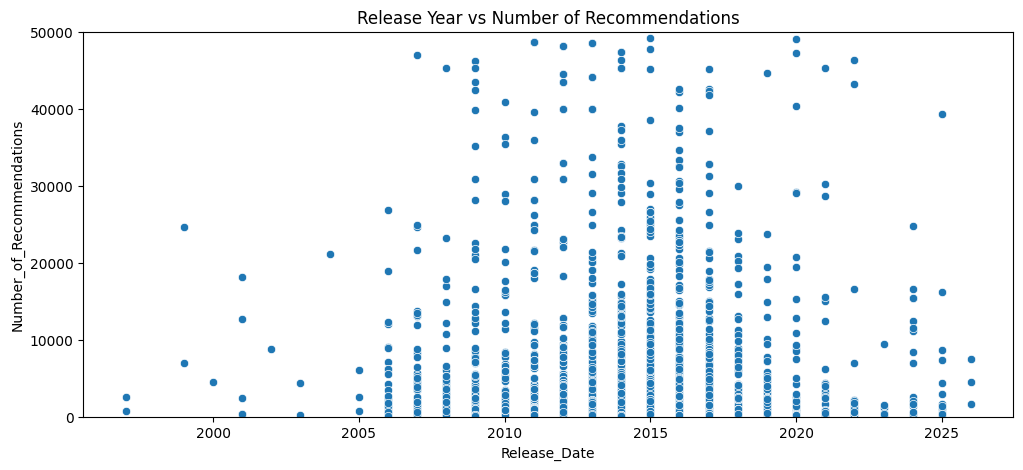

In [35]:
plt.figure(figsize=(12,5))
sns.scatterplot(data = df, x = df['Release_Date'].dt.year, y = 'Number_of_Recommendations')
plt.title('Release Year vs Number of Recommendations')
plt.ylim(0, 50000)
plt.show()

### Conclusion 

Again the years 2009-2017 peaked in the number of recommendations which makes sense as we mentioned before these were revolutionary years for the gaming, however, that doesn't mean that +2018 had fewer recommendations because they were worse but maybe because of the limited time they had to accumulate the recommendations as earlier years had more time 

## SQL Analysis

To further explore the dataset, we will use SQL queries to analyze key aspects of the games. The following queries will help identify trends in **recommendations, pricing, and game development**:

1. **Top Genres by Average Recommendations**
   Calculate the average number of recommendations for each genre and identify the genres with the highest average.

2. **Average Price by Genre**
   Analyze the average game price for each genre to compare pricing patterns across different genres.

3. **Top Developers by Number of Games**
   Count the number of games developed by each developer and identify the developers with the largest number of games in the dataset.


In [3]:
import sqlite3

conn = sqlite3.connect(':memory:')
df.to_sql('games', conn, index= False, if_exists= 'replace')

10249

In [5]:
test = pd.read_sql('''
SELECT * FROM GAMES LIMIT 1
''', conn)
test

,Game_ID,Game_Name,Is_Free,Description,Supported_Languages,Developer,Publishers,Price,Genre,Category,Number_of_Recommendations,Release_Date
0,10,Counter-Strike,0,Play the world's number 1 online action game. ...,"English, French, German, Italian, Spanish - Sp...",Valve,Valve,5.79,Action,"Multi-player,PvP,Online PvP,Shared/Split Scree...",168033.0,2000-11-01


In [8]:
top_genre_sql = pd.read_sql('''
SELECT GENRE, AVG(NUMBER_OF_RECOMMENDATIONS) AS AVG_RECOMMENDATIONS
FROM GAMES
GROUP BY GENRE
ORDER BY AVG_RECOMMENDATIONS DESC
LIMIT 10
''', conn)
top_genre_sql

,Genre,AVG_RECOMMENDATIONS
0,"Action,Free To Play",494055.538462
1,"Racing,Simulation,Early Access",365639.000000
2,"Action,Adventure,Indie,Massively Multiplayer,RPG",351548.000000
3,"Action,Adventure,Massively Multiplayer",254211.000000
4,"Action,Indie,Massively Multiplayer,Strategy",175896.000000
5,"Indie,RPG,Simulation,Early Access",171094.250000
6,"Indie,RPG,Simulation",145222.833333
7,"Action,Adventure,Free To Play,Massively Multip...",143107.000000
8,"Action,Adventure,Indie,RPG,Simulation,Strategy",80800.625000
9,"Action,Adventure,Massively Multiplayer,RPG,Sim...",79446.500000


In [10]:
avg_genre_price = pd.read_sql('''
SELECT GENRE, AVG(PRICE) AS AVERAGE_PRICE
FROM GAMES
GROUP BY GENRE
ORDER BY AVERAGE_PRICE DESC
LIMIT 10
''',conn)

avg_genre_price

,Genre,AVERAGE_PRICE
0,"Action,Adventure,Massively Multiplayer",34.323333
1,"Casual,Indie,RPG,Simulation,Strategy",32.995000
2,"Action,RPG,Simulation",31.792000
3,"Action,Indie,Massively Multiplayer,Simulation,...",29.990000
4,"Action,Adventure,Indie,Massively Multiplayer,R...",29.990000
5,"Action,Indie,Massively Multiplayer,Strategy",26.495000
6,"Violent,Action,Indie,Early Access",24.990000
7,"Racing,Simulation,Sports,Strategy,Early Access",24.990000
8,"Action,Adventure,Casual,Indie,Massively Multip...",24.990000
9,"Action,Adventure,Casual,Indie,Massively Multip...",24.990000


In [13]:
top_devs_by_popularity = pd.read_sql('''
SELECT DEVELOPER, COUNT(*) AS NUMBER_OF_GAMES
FROM GAMES 
GROUP BY DEVELOPER 
ORDER BY NUMBER_OF_GAMES DESC
LIMIT 10
''', conn)
top_devs_by_popularity

,Developer,NUMBER_OF_GAMES
0,Unknown,40
1,MumboJumbo,37
2,Humongous Entertainment,36
3,Choice of Games,30
4,Spiderweb Software,25
5,Daedalic Entertainment,25
6,HeR Interactive,24
7,"PopCap Games, Inc.",23
8,Dharker Studios,23
9,Valve,20


In [15]:
#ind the average price and total recommendations for each release year, but only include years with more than 50 games:
avg_price_per_year = pd.read_sql('''
SELECT strftime('%Y',RELEASE_DATE) AS YEAR, COUNT(*) AS NUMBER_OF_GAMES, AVG(PRICE) AS AVERAGE_PRICE, SUM(NUMBER_OF_RECOMMENDATIONS) AS NUMBER_OF_RECOMMENDATIONS
FROM GAMES
GROUP BY YEAR
HAVING NUMBER_OF_GAMES > 50 
ORDER BY NUMBER_OF_GAMES DESC
LIMIT 10
''',conn)
avg_price_per_year

,YEAR,NUMBER_OF_GAMES,AVERAGE_PRICE,NUMBER_OF_RECOMMENDATIONS
0,2016,2753,6.395390,7933611.0
1,2015,2373,6.263843,6969845.0
2,2014,1458,7.043505,4207013.0
3,2017,694,9.019971,3845077.0
4,2012,536,7.673675,8981482.0
5,2013,508,7.910768,4957078.0
6,2011,336,6.970357,3716537.0
7,2018,294,9.719048,4254695.0
8,2009,280,7.359429,1670427.0
9,2010,223,6.951704,1106074.0


### Results

The results show that **2016 had the highest number of games (2,753)**, while **2012 had the highest total number of recommendations (8.98 million)** despite having only **536 games**. This suggests that the games released in 2012 received significantly more recommendations on average, likely due to the popularity of several games released during that year.
